In [17]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from pathlib import Path
import contextlib
import io

In [18]:
output_dir = Path("outputs_OI_SNRinf_1e5")
output_dir.mkdir(exist_ok=True)

In [19]:
def standardize_spectrum(X):
    mean = np.nanmean(X, axis=1, keepdims=True)
    std = np.nanstd(X, axis=1, keepdims=True)

    std[std == 0] = 1.0

    X_std = (X - mean) / std
    X_std[~np.isfinite(X_std)] = 0.0

    return X_std.astype(np.float32)

In [20]:
def FNN(input_dim, dropout_rate):
    model = models.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(1e-5)),
        layers.Dropout(dropout_rate),
        layers.Dense(32, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(1e-5)),
        layers.Dropout(dropout_rate),
        layers.Dense(4, activation="softmax")])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
        loss="mse",
        metrics=[
            tf.keras.metrics.MeanAbsoluteError(name="mae"),
            tf.keras.metrics.CategoricalAccuracy(name="dominant_acc")])

    return model

In [21]:
def count_dominant_classes(y_split, split_name, class_names):
    dominant_indices = np.argmax(y_split, axis=1)
    counts = pd.Series(dominant_indices).value_counts().sort_index()
    result = pd.DataFrame({"class": class_names, "count": [counts.get(i, 0) for i in range(len(class_names))]})

    result["percentage"] = 100 * result["count"] / len(y_split)

    print(f"\n{split_name}:")
    print(result.to_string(index=False))

In [22]:
class_names = ["HII", "PN", "SNR", "DIG"]

data_dir = Path("../Mock Spectra")

X = np.load(data_dir / "mock_spectra_combined_OI_SNRinf_1e5.npy")
y = np.load(data_dir / "mock_spectra_combined_weights_OI_SNRinf_1e5.npy")
metadata = pd.read_csv(data_dir / "mock_spectra_combined_metadata_OI_SNRinf_1e5.csv")

X = X.astype(np.float32)
y = y.astype(np.float32)

print("X shape:", X.shape)
print("Y shape:", y.shape)

X shape: (100000, 3841)
Y shape: (100000, 4)


In [23]:
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [24]:
X = standardize_spectrum(X)

#dominant_class = np.argmax(y, axis=1)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    shuffle=True,
    #stratify=dominant_class
    )

#temp_dominant_class = np.argmax(y_temp, axis=1)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    shuffle=True,
    #stratify=temp_dominant_class
    )

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape, y_val.shape)
print("Test: ", X_test.shape, y_test.shape)

count_dominant_classes(y_train, "Training set", class_names)
count_dominant_classes(y_val, "Validation set", class_names)
count_dominant_classes(y_test, "Test set", class_names)

Train: (70000, 3841) (70000, 4)
Val:   (15000, 3841) (15000, 4)
Test:  (15000, 3841) (15000, 4)

Training set:
class  count  percentage
  HII  17398   24.854286
   PN  17497   24.995714
  SNR  17510   25.014286
  DIG  17595   25.135714

Validation set:
class  count  percentage
  HII   3751   25.006667
   PN   3757   25.046667
  SNR   3773   25.153333
  DIG   3719   24.793333

Test set:
class  count  percentage
  HII   3693       24.62
   PN   3807       25.38
  SNR   3735       24.90
  DIG   3765       25.10


In [25]:
model = FNN(X.shape[1], dropout_rate=0.3)
model.summary()

early_stop = callbacks.EarlyStopping(
    monitor="val_mae",
    patience=10,
    restore_best_weights=True)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=256,
    callbacks=[early_stop])

'''
early_stop = callbacks.EarlyStopping(
    monitor="val_mae",
    patience=25,
    restore_best_weights=True,
    mode="min")

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_mae",
    factor=0.5,
    patience=8,
    min_lr=1e-6,
    mode="min")

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=500,
    batch_size=128,
    callbacks=[early_stop, reduce_lr])
'''   
with open(output_dir / "model_summary.txt", "w") as f:
    model.summary(print_fn=lambda line: f.write(line + "\n"))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │       245,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 248,100 (969.14 KB)

 Trainable params: 248,100 (969.14 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - dominant_acc: 0.5639 - loss: 0.0475 - mae: 0.1552 - val_dominant_acc: 0.6771 - val_loss: 0.0295 - val_mae: 0.1207
Epoch 2/100
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - dominant_acc: 0.6474 - loss: 0.0335 - mae: 0.1275 - val_dominant_acc: 0.6911 - val_loss: 0.0254 - val_mae: 0.1098
Epoch 3/100
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - dominant_acc: 0.6635 - loss: 0.0300 - mae: 0.1197 - val_dominant_acc: 0.6979 - val_loss: 0.0230 - val_mae: 0.1038
Epoch 4/100
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - dominant_acc: 0.6739 - loss: 0.0275 - mae: 0.1143 - val_dominant_acc: 0.7072 - val_loss: 0.0216 - val_mae: 0.1003
Epoch 5/100
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - dominant_acc: 0.6843 - loss: 0.0259 - mae: 0.1104 - val_dominant_acc: 0.7137 - val_loss: 0.0203 - val_mae: 0.0961
Epoch 6/100
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - dominant_acc: 0.6904 - loss: 0.0245 - mae: 0.1072 - val_dominant_acc: 0.7169 - val_loss: 0.0194 - va

In [26]:
test_results = model.evaluate(X_test, y_test, return_dict=True)
print("Test metrics:")
for name, value in test_results.items():
    print(f"  {name}: {value:.4f}")

with open(output_dir / "test_metrics.txt", "w") as f:
    f.write("Test metrics:\n")
    for name, value in test_results.items():
        f.write(f"{name}: {value:.6f}\n")    

y_pred = model.predict(X_test)

y_true_class = np.argmax(y_test, axis=1)
y_pred_class = np.argmax(y_pred, axis=1)

report = classification_report(
    y_true_class,
    y_pred_class,
    target_names=class_names,
    digits=3)
print(report)

with open(output_dir / "classification_report_all.txt", "w") as f:
    f.write(report)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 344us/step - dominant_acc: 0.7821 - loss: 0.0119 - mae: 0.0715
Test metrics:
  dominant_acc: 0.7821
  loss: 0.0119
  mae: 0.0715
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 225us/step
              precision    recall  f1-score   support

         HII      0.718     0.792     0.753      3693
          PN      0.808     0.768     0.787      3807
         SNR      0.827     0.860     0.843      3735
         DIG      0.780     0.710     0.744      3765

    accuracy                          0.782     15000
   macro avg      0.783     0.782     0.782     15000
weighted avg      0.784     0.782     0.782     15000



In [27]:
absolute_errors = np.abs(y_test - y_pred)
median_absolute_error = np.median(absolute_errors, axis=0)
mean_absolute_error = np.mean(absolute_errors, axis=0)

weight_error_table = pd.DataFrame({
    "class": class_names,
    "median_absolute_error": median_absolute_error,
    "mean_absolute_error": mean_absolute_error,
    "median_error_percent": 100 * median_absolute_error})

print("Overall median absolute error:", np.median(absolute_errors))
weight_error_table

weight_error_table.to_csv(output_dir / "weight_error_table.csv", index=False)

with open(output_dir / "weight_error_table.txt", "w") as f:
    f.write(f"Overall median absolute error: {np.median(absolute_errors):.6f}\n")
    f.write(f"Overall mean absolute error: {np.mean(absolute_errors):.6f}\n\n")
    f.write(weight_error_table.to_string(index=False))

Overall median absolute error: 0.04824546


In [28]:
prevalent_mask = np.max(y_test, axis=1) > 0.5

print("Spectra with a weight > 0.5:", prevalent_mask.sum())

report_prevalent = classification_report(
    y_true_class[prevalent_mask],
    y_pred_class[prevalent_mask],
    target_names=class_names,
    digits=3)
print(report_prevalent)

with open(output_dir / "classification_report_weight_above_0p5.txt", "w") as f:
    f.write(f"Spectra with a weight > 0.5: {prevalent_mask.sum()}\n\n")

Spectra with a weight > 0.5: 8904
              precision    recall  f1-score   support

         HII      0.893     0.926     0.909      2193
          PN      0.918     0.927     0.922      2247
         SNR      0.942     0.959     0.950      2239
         DIG      0.937     0.876     0.906      2225

    accuracy                          0.922      8904
   macro avg      0.922     0.922     0.922      8904
weighted avg      0.922     0.922     0.922      8904



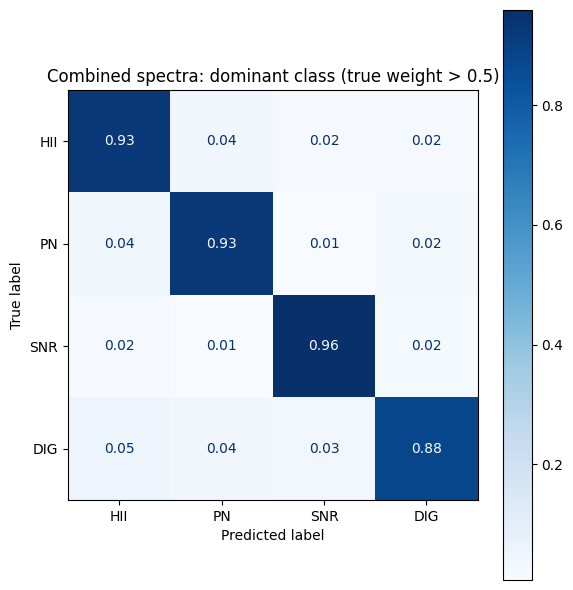

In [29]:
cm = confusion_matrix(
    y_true_class[prevalent_mask],
    y_pred_class[prevalent_mask],
    normalize="true")

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, values_format=".2f", cmap="Blues")
plt.title("Combined spectra: dominant class (true weight > 0.5)")
plt.tight_layout()
plt.savefig(output_dir / "confusion_matrix_weight_above_0p5.png", dpi=300)
plt.show()

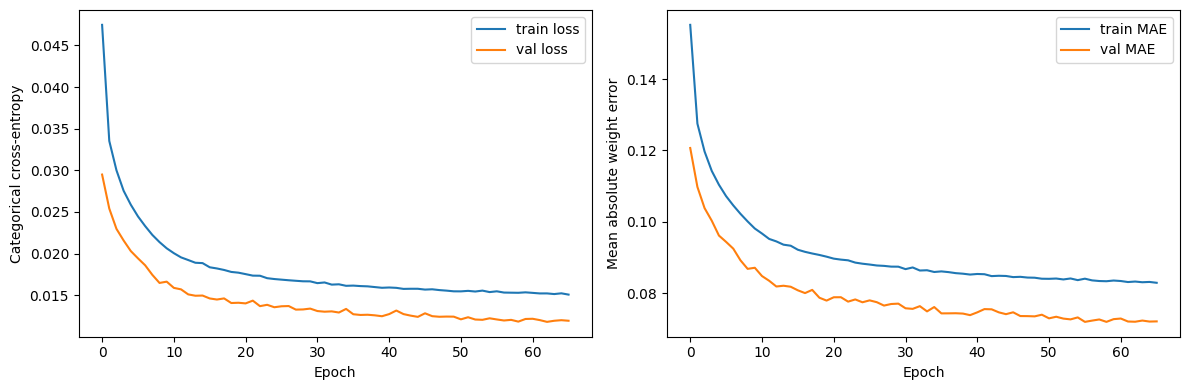

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="train loss")
axes[0].plot(history.history["val_loss"], label="val loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Categorical cross-entropy")
axes[0].legend()

axes[1].plot(history.history["mae"], label="train MAE")
axes[1].plot(history.history["val_mae"], label="val MAE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Mean absolute weight error")
axes[1].legend()

plt.tight_layout()
plt.savefig(output_dir / "training_curves.png", dpi=300)
plt.show()

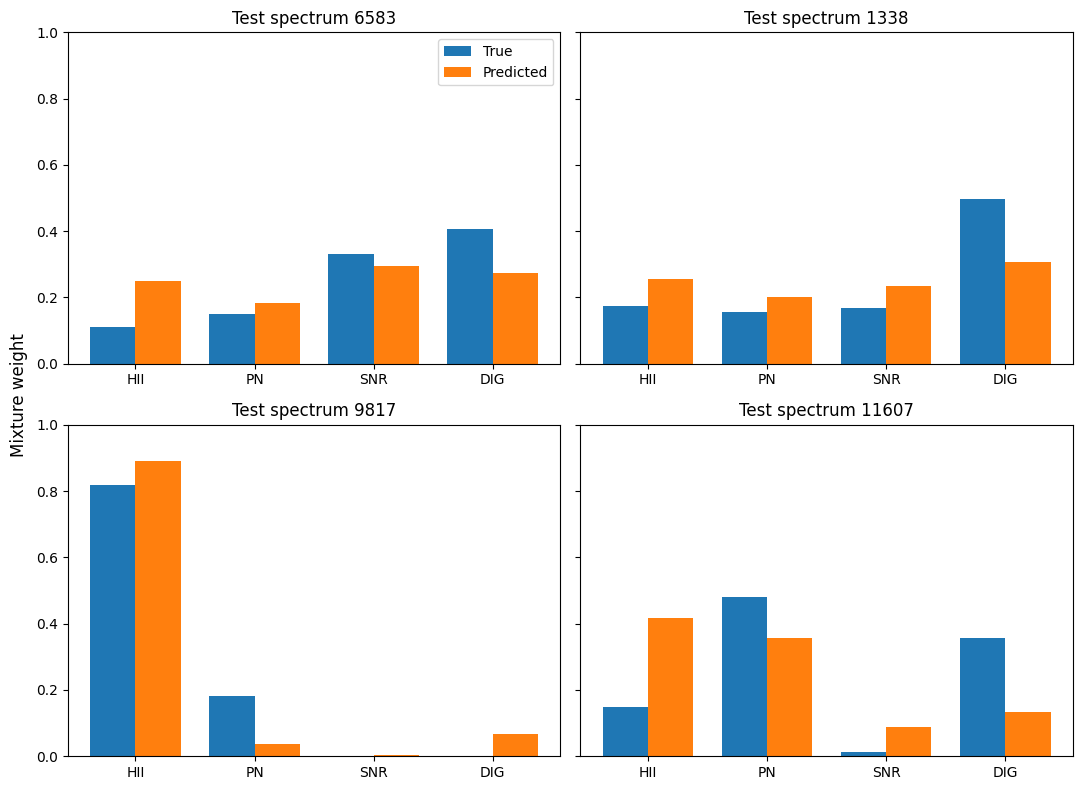

In [31]:
rng = np.random.default_rng(SEED)
example_indices = rng.choice(len(y_test), size=4, replace=False)
x_positions = np.arange(len(class_names))
bar_width = 0.38

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)

for ax, index in zip(axes.flat, example_indices):
    ax.bar(
        x_positions - bar_width / 2,
        y_test[index],
        width=bar_width,
        label="True")
    ax.bar(
        x_positions + bar_width / 2,
        y_pred[index],
        width=bar_width,
        label="Predicted")
    ax.set_xticks(x_positions, class_names)
    ax.set_ylim(0, 1)
    ax.set_title(f"Test spectrum {index}")

axes[0, 0].legend()
fig.supylabel("Mixture weight")
plt.tight_layout()
plt.savefig(output_dir / "example_weight_predictions.png", dpi=300)
plt.show()

In [16]:
#model.save("fnn_combined_spectra.keras")